In [112]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Data Source: https://data-nifc.opendata.arcgis.com/datasets/nifc::wfigs-interagency-fire-perimeters/about

df = pd.read_csv("WFIGS_Interagency_Perimeters_-8039255302361386572.csv", low_memory=False)

df = df[df["attr_POOState"] == "US-OR"] # filter by Oregon only
df = df.dropna(subset=["attr_IncidentSize", "attr_DiscoveryAcres"]) # drops rows that don't have initial or final acreages

# drops data smaller than the dataset's specified minimum
df = df[df["attr_DiscoveryAcres"] > 0.01] 
df = df[df['attr_IncidentSize'] > 0.1]

# display(df)


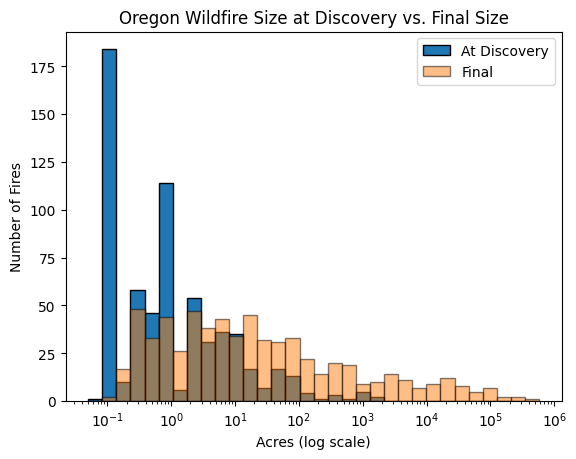

In [ ]:
mins = min(df["attr_DiscoveryAcres"].min(), df["attr_IncidentSize"].min())
maxs = max(df["attr_DiscoveryAcres"].max(), df["attr_IncidentSize"].max())
bins = np.logspace(np.log10(mins), np.log10(maxs), 33)
plt.hist(df["attr_DiscoveryAcres"], bins=bins, label="At Discovery", edgecolor="k")
plt.hist(df["attr_IncidentSize"], bins=bins, alpha=0.5, label="Final", edgecolor="k")
plt.title("Oregon Wildfire Size at Discovery vs. Final Size")
plt.xscale("log")
plt.xlabel("Acres (log scale)")
plt.ylabel("Number of Fires")
plt.legend()
plt.show()

# Some Notes:
# 1. You will notice that most fires were .1 acres when discovered (over 175). While some of these fires were actually .1 acres upon discovery, 
# it is likely many are the result of firefighters inserting a default value without all the information.
# 2. A log scale was used on all graphs because of the large clustering at the low end and very large outliers.


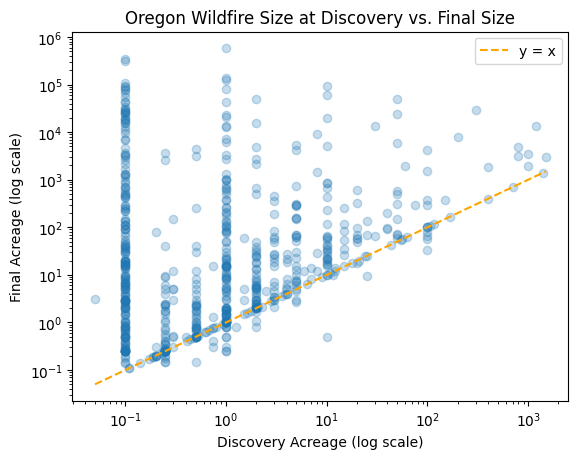

In [129]:
plt.scatter(df["attr_DiscoveryAcres"], df["attr_IncidentSize"], alpha=0.25)
lims = [df["attr_DiscoveryAcres"].min(), df["attr_DiscoveryAcres"].max()]
plt.plot(lims, lims, color="orange", linestyle="--", label="y = x")
plt.title("Oregon Wildfire Size at Discovery vs. Final Size")
plt.xscale("log")
plt.xlabel("Discovery Acreage (log scale)")
plt.yscale("log")
plt.ylabel("Final Acreage (log scale)")
plt.legend()
plt.show()

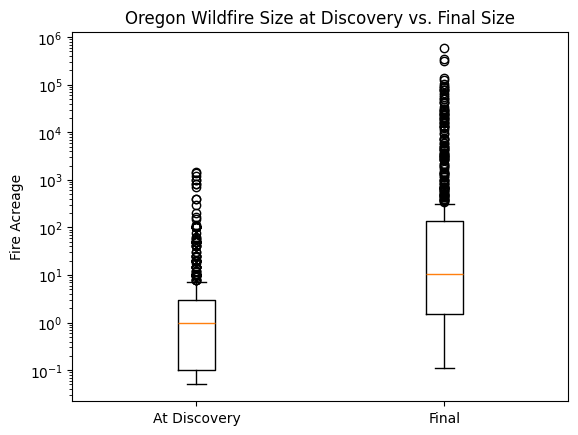

[5.0e-02 1.0e-01 1.0e+00 3.0e+00 1.5e+03]
[1.10000e-01 1.50000e+00 1.07500e+01 1.34380e+02 5.78637e+05]


In [ ]:
plt.boxplot([df["attr_DiscoveryAcres"], df["attr_IncidentSize"]], tick_labels=["At Discovery", "Final"])
plt.title("Oregon Wildfire Size at Discovery vs. Final Size")
plt.yscale("log")
plt.ylabel("Acres (log scale)")
plt.show()

print(np.percentile(df["attr_DiscoveryAcres"], [0, 25, 50, 75, 100]))
print(np.percentile(df["attr_IncidentSize"], [0, 25, 50, 75, 100]))